Prepared fold 1: 7000 augmented train, 400 original validation
Prepared fold 2: 8400 augmented train, 200 original validation
Prepared fold 3: 8400 augmented train, 200 original validation
Prepared fold 4: 7000 augmented train, 400 original validation
Prepared fold 5: 8400 augmented train, 200 original validation
DATA SUMMARY
Original frames: 1400
Input shape: (1400, 24, 32, 1)
Background frames: 118


Class,Clean Air,HFC
Session,,
1,100,100
2,100,100
3,100,100
4,100,100
5,100,100
6,100,100
7,100,100


,Original validation frames
validation_fold,
1,400
2,200
3,200
4,400
5,200


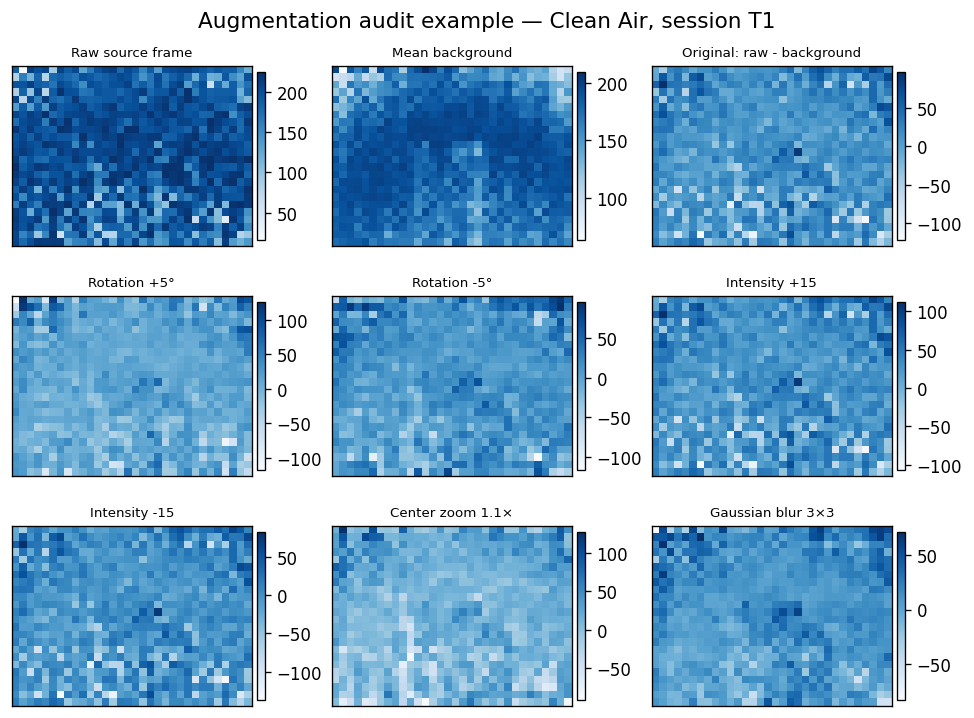

Source: C:\1. Tukadi_ITS\X_learning5\Clean Air\Non HFC (1).csv

Folder hasil: C:\Users\tukadi\OneDrive\Documents\ChatGPT\New project\ijies_master_outputs | 5 fold | 1400 prediksi validasi (frame asli) | id protokol: 463e390e2666
[1] ✓ Fold & label identik dengan hasil lama (4 classifier lama diperiksa dari prediksi tersimpan).

[1b] DIAGNOSTIK PRA-PROSES (data riil Anda):
     frame asli di TRAIN vs frame yang sama (float) seperti di VALIDASI: selisih rata-rata = +0.000, SD = 0.000, maks |selisih| = 0.000 (satuan data)
     SD ΔT data = 38.390; offset augmentasi ±15 = 0.4 × SD data.

[2] Tabel lama dari table13_summary.csv: 5 baris


,classifier,pooled_accuracy,pooled_macro_f1,fold_accuracy_mean,fold_accuracy_sample_sd
0,Random forest,0.8829,0.8823,0.8925,0.0361
1,RBF SVM,0.8286,0.8282,0.8335,0.0240
2,Proposed compact CNN,0.8029,0.8026,0.8095,0.0403
3,Linear SVM,0.7479,0.7458,0.7515,0.0156
4,K-nearest neighbors,0.7229,0.7126,0.7195,0.0296



[3] Menghitung 10 classifier baru (classifier lama TIDAK dijalankan):
  Logistic regression            pooled accuracy=0.7207 | 2.0s
  Linear discriminant analysis   pooled accuracy=0.6957 | 2.9s
  Ridge classifier               pooled accuracy=0.6957 | 0.5s
  Gaussian naive Bayes           pooled accuracy=0.6050 | 0.5s
  MLP (sklearn)                  pooled accuracy=0.8021 | 16.3s
  Extra trees                    pooled accuracy=0.8921 | 9.1s
  Decision tree                  pooled accuracy=0.7493 | 22.5s
  AdaBoost                       pooled accuracy=0.6264 | 178.4s
  Histogram gradient boosting    pooled accuracy=0.8393 | 29.0s
  Gradient boosting              pooled accuracy=0.6521 | 167.3s

✓ 5 baris lama tidak diubah | 10 classifier baru ditambahkan.
TABLE 13 DIPERLUAS — diurutkan dari akurasi terbaik


rank,classifier,pooled_accuracy,pooled_macro_f1,fold_accuracy_mean,fold_accuracy_sample_sd,source
1,Extra trees,0.8921,0.8910,0.9025,0.0340,new
2,Random forest,0.8829,0.8823,0.8925,0.0361,existing
3,Histogram gradient boosting,0.8393,0.8389,0.8400,0.0177,new
4,RBF SVM,0.8286,0.8282,0.8335,0.0240,existing
5,Proposed compact CNN,0.8029,0.8026,0.8095,0.0403,existing
6,MLP (sklearn),0.8021,0.8002,0.8070,0.0255,new
7,Decision tree,0.7493,0.7450,0.7630,0.0448,new
8,Linear SVM,0.7479,0.7458,0.7515,0.0156,existing
9,K-nearest neighbors,0.7229,0.7126,0.7195,0.0296,existing
10,Logistic regression,0.7207,0.7193,0.7250,0.0218,new


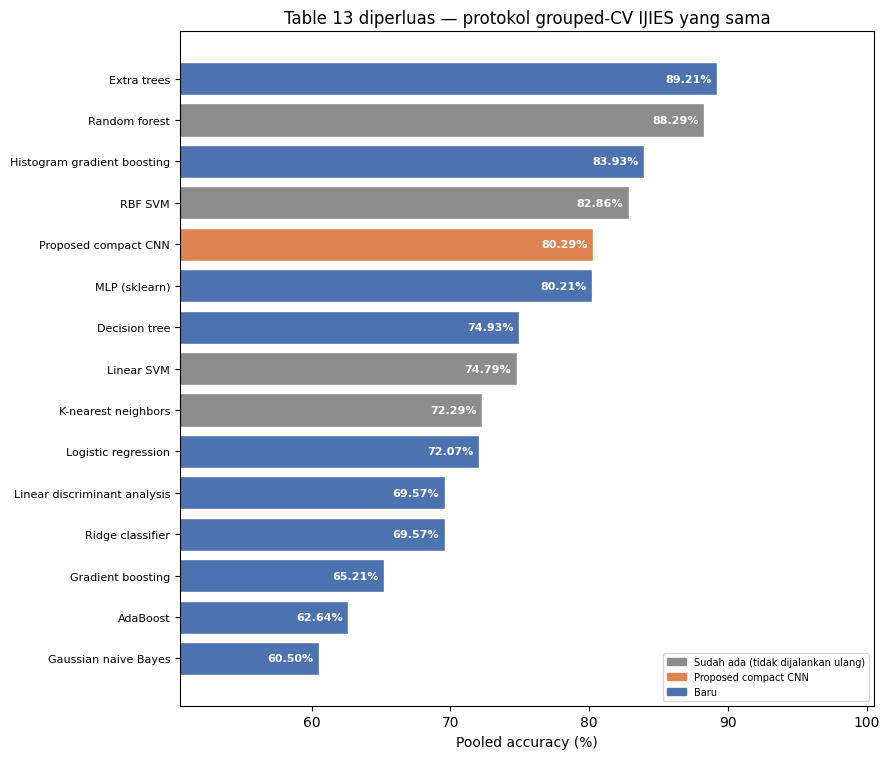


CNN vs CLASSIFIER — selisih akurasi dengan bootstrap per-SESI (7 sesi, 5000 resampel)


,classifier,pooled_acc (%),CNN − classifier (poin),CI95 bawah,CI95 atas,P(CNN lebih baik)
0,Extra trees,89.21,-8.93,-11.64,-6.79,0.00
1,Random forest,88.29,-8.00,-10.71,-6.07,0.00
2,Histogram gradient boosting,83.93,-3.64,-6.93,-0.21,0.02
3,RBF SVM,82.86,-2.57,-5.86,0.50,0.06
4,MLP (sklearn),80.21,0.07,-2.86,2.93,0.52
5,Decision tree,74.93,5.36,2.43,8.08,1.00
6,Linear SVM,74.79,5.50,3.21,8.21,1.00
7,K-nearest neighbors,72.29,8.00,3.71,12.86,1.00
8,Logistic regression,72.07,8.21,5.36,11.29,1.00
9,Linear discriminant analysis,69.57,10.71,6.71,15.14,1.00


⚠ Hanya 7 sesi: interval lebar. Jika CI melewati 0, selisihnya tidak dapat dibedakan dari nol pada tingkat sesi.

✓ Tersimpan di C:\Users\tukadi\OneDrive\Documents\ChatGPT\New project\ijies_master_outputs: table13_additional_source_predictions.csv, table13_additional_summary.csv, table13_extended_summary.csv, table13_extended_ranking.png, table13_paired_vs_cnn.csv


In [1]:
"""Table 13 — tambah classifier baru, SATU SEL (pipeline IJIES + classifier tambahan).

Bagian 1 menyiapkan data persis seperti sel pipeline IJIES (1.400 frame asli, 5 fold grouped-sesi, augmentasi hanya pada TRAIN).
Bagian 2 menambah classifier baru tanpa menjalankan ulang classifier lama (hasil lama dibaca dari file yang tersimpan).
Tidak ada classifier lama / CNN yang dilatih di sel ini.
"""

from __future__ import annotations

from dataclasses import dataclass
from hashlib import sha256
from pathlib import Path
import os, random, re, time, warnings

import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import tensorflow as tf
warnings.filterwarnings("ignore")

from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import (AdaBoostClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier)
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

try:
    display
except NameError:
    def display(x): print((x.data if hasattr(x, "data") else x).to_string())

# ---------------- KONFIGURASI ----------------
CLASSIFIERS_TO_RUN     = None     # None = semua; atau mis. ["Logistic regression", "Extra trees"]
SEED                   = 42
FORCE_RERUN            = False    # True = abaikan prediksi tersimpan dan hitung ulang classifier BARU
RUN_PAIRED_VS_CNN      = True     # perbandingan berpasangan terhadap CNN (bootstrap per-sesi) dari prediksi tersimpan
N_BOOT                 = 5000
SHOW_AUGMENTATION_AUDIT = True    # tampilkan ringkasan data + contoh augmentasi (seperti sel pipeline asli)

# ================================================================
# BAGIAN 1 — PIPELINE IJIES (persiapan data; sama dengan sel pipeline Anda)
# ================================================================
@dataclass(frozen=True)
class Config:
    original_root: str = r"C:\1. Tukadi_ITS\X_learning5"
    holdout_root: str = r"C:\1. Tukadi_ITS\X_testing5"
    output_dir: str = r"C:\Users\tukadi\OneDrive\Documents\ChatGPT\New project\ijies_master_outputs"
    seed: int = 42
    n_splits: int = 5
    max_epochs: int = 50
    patience: int = 30
    batch_size: int = 32
    learning_rate: float = 0.001
    images_per_class_session: int = 100
    expected_original: int = 1400
    run_pair_ablations: bool = False


LABEL_TO_ID = {"Clean Air": 0, "HFC": 1}


def seed_all(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)


def read_frame(path):
    try: a = pd.read_csv(path, header=None).to_numpy(dtype=np.float32)
    except Exception: return None
    if a.shape == (24, 32): return a
    return a.reshape(24, 32) if a.size == 768 else None


def number(path):
    m = re.search(r"\((\d+)\)", Path(path).stem)
    if not m: raise ValueError(f"Missing sequence number: {path}")
    return int(m.group(1))


def file_hash(path):
    h = sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""): h.update(block)
    return h.hexdigest()


def load_master(config=Config()):
    root, out = Path(config.original_root), Path(config.output_dir)
    out.mkdir(parents=True, exist_ok=True); seed_all(config.seed)
    bg_paths, bg_frames = [], []
    for p in sorted((root / "Background").glob("*.csv")):
        a = read_frame(p)
        if a is not None: bg_paths.append(str(p)); bg_frames.append(a)
    if not bg_frames: raise RuntimeError("No valid background frames")
    background = np.mean(np.stack(bg_frames), axis=0).astype(np.float32)
    raw, labels, groups, paths = [], [], [], []
    for name, label in LABEL_TO_ID.items():
        for p in sorted((root / name).glob("*.csv")):
            a = read_frame(p)
            if a is None: continue
            raw.append(a); labels.append(label)
            groups.append((number(p) - 1) // config.images_per_class_session)
            paths.append(str(p))
    raw = np.asarray(raw, np.float32); y = np.asarray(labels, int)
    groups, paths = np.asarray(groups, int), np.asarray(paths)
    if len(raw) != config.expected_original: raise ValueError(f"Expected {config.expected_original}, found {len(raw)}")
    delta = (raw - background)[..., None]
    splits = list(StratifiedGroupKFold(config.n_splits, shuffle=True, random_state=config.seed).split(delta, y, groups))
    fold_of = np.full(len(y), -1, int)
    for fold, (tr, va) in enumerate(splits, 1):
        assert not (set(groups[tr]) & set(groups[va])); fold_of[va] = fold
    manifest = pd.DataFrame({"source_index":np.arange(len(y)),"path":paths,"label":y,"session":groups,"validation_fold":fold_of})
    manifest.to_csv(out / "source_fold_manifest.csv", index=False)
    pd.DataFrame({"path":bg_paths,"sha256":[file_hash(p) for p in bg_paths]}).to_csv(out / "background_manifest.csv", index=False)
    return {"config":config,"out":out,"raw":raw,"delta":delta,"y":y,"groups":groups,"paths":paths,
            "background":background,"background_paths":bg_paths,"splits":splits,"manifest":manifest}


def variants(raw):
    raw = np.clip(raw, 0, 255).astype(np.uint8); h, w = raw.shape
    center = (w // 2, h // 2)
    def rot(angle):
        m = cv2.getRotationMatrix2D(center, angle, 1.0)
        return cv2.warpAffine(raw, m, (w, h), borderMode=cv2.BORDER_REFLECT)
    nw, nh = int(w / 1.1), int(h / 1.1); x0, y0 = w//2-nw//2, h//2-nh//2
    zoom = cv2.resize(raw[y0:y0+nh, x0:x0+nw], (w,h), interpolation=cv2.INTER_LINEAR)
    return [raw, rot(5), rot(-5), np.clip(raw.astype(np.int16)+15,0,255).astype(np.uint8),
            np.clip(raw.astype(np.int16)-15,0,255).astype(np.uint8), zoom, cv2.GaussianBlur(raw,(3,3),0)]


def augment(raw, y, background):
    xx, yy = [], []
    for frame, label in zip(raw, y):
        for v in variants(frame): xx.append((v.astype(np.float32)-background)[...,None]); yy.append(label)
    return np.asarray(xx,np.float32), np.asarray(yy,int)


def prepared_folds(master):
    cache = []
    for fold, (tr, va) in enumerate(master["splits"], 1):
        xtr, ytr = augment(master["raw"][tr], master["y"][tr], master["background"])
        cache.append({"fold":fold,"tr":tr,"va":va,"xtr":xtr,"ytr":ytr,
                      "xva":master["delta"][va],"yva":master["y"][va]})
        print(f"Prepared fold {fold}: {len(xtr)} augmented train, {len(va)} original validation")
    return cache


def show_data_and_augmentation(master, sample_index=0):
    """Display data counts and one auditable augmentation example."""
    if not 0 <= sample_index < len(master["raw"]):
        raise IndexError(f"sample_index must be between 0 and {len(master['raw'])-1}")
    label_names = {value: key for key, value in LABEL_TO_ID.items()}
    counts = pd.crosstab(
        pd.Series(master["groups"] + 1, name="Session"),
        pd.Series([label_names[int(v)] for v in master["y"]], name="Class"),
    )
    fold_counts = master["manifest"].groupby("validation_fold").size().rename("Original validation frames")
    print("DATA SUMMARY")
    print("Original frames:", len(master["raw"]))
    print("Input shape:", master["delta"].shape)
    print("Background frames:", len(master["background_paths"]))
    display(counts)
    display(fold_counts.to_frame())

    raw = master["raw"][sample_index]
    background = master["background"]
    processed = [(v.astype(np.float32) - background) for v in variants(raw)]
    images = [raw, background, *processed]
    titles = [
        "Raw source frame", "Mean background", "Original: raw - background",
        "Rotation +5°", "Rotation -5°", "Intensity +15",
        "Intensity -15", "Center zoom 1.1×", "Gaussian blur 3×3",
    ]
    fig, axes = plt.subplots(3, 3, figsize=(8, 6), dpi=120, constrained_layout=True)
    for ax, image, title in zip(axes.ravel(), images, titles):
        artist = ax.imshow(image, cmap="Blues")
        ax.set_title(title, fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(artist, ax=ax, fraction=0.040, pad=0.02, shrink=0.80)
    label = label_names[int(master["y"][sample_index])]
    session = int(master["groups"][sample_index]) + 1
    fig.suptitle(f"Augmentation audit example — {label}, session T{session}", fontsize=13)
    plt.show()
    print("Source:", master["paths"][sample_index])


# Muat 1.400 frame asli, bentuk lima fold grouped-sesi, dan buat augmentasi hanya dari sumber TRAIN tiap fold.
config = Config()
master = load_master(config)
fold_cache = prepared_folds(master)
if SHOW_AUGMENTATION_AUDIT:
    show_data_and_augmentation(master, sample_index=0)

# ================================================================
# BAGIAN 2 — TABLE 13: TAMBAH CLASSIFIER BARU (classifier lama TIDAK dijalankan ulang)
# Hasil lama dibaca dari file yang sudah tersimpan (table13_summary.csv, *_source_predictions.csv).
# Tahan mati laptop: prediksi tiap classifier baru langsung disimpan; dijalankan ulang -> yang sudah selesai dilewati.
# ================================================================
OUT = Path(master["out"])
TOTAL_VA = int(sum(len(p["va"]) for p in fold_cache))
PROTOCOL_ID = sha256(np.concatenate([p["va"] for p in fold_cache]).tobytes() + b"|aug7_v1").hexdigest()[:12]
PRED_NEW = OUT / "table13_additional_source_predictions.csv"
SUM_NEW  = OUT / "table13_additional_summary.csv"
SUM_EXT  = OUT / "table13_extended_summary.csv"
COLS = ["classifier", "pooled_accuracy", "pooled_macro_f1", "fold_accuracy_mean", "fold_accuracy_sample_sd"]
print(f"\nFolder hasil: {OUT} | {len(fold_cache)} fold | {TOTAL_VA} prediksi validasi (frame asli) | id protokol: {PROTOCOL_ID}")

def _metric_row(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    return accuracy_score(y, pred), p, r, f

# ================================================================
# 1) PEMERIKSAAN FOLD TERHADAP HASIL LAMA — dari prediksi tersimpan (tidak ada classifier lama yang dijalankan)
# ================================================================
old_pred_path = OUT / "table13_source_predictions.csv"
old_pred = pd.read_csv(old_pred_path) if old_pred_path.exists() else None
if old_pred is not None:
    for name, g in old_pred.groupby("classifier", sort=False):
        for pack in fold_cache:
            a = g[g.fold == pack["fold"]].sort_values("source_index")
            assert np.array_equal(a.source_index.values, np.sort(pack["va"])), \
                f"Fold {pack['fold']} berbeda dari hasil lama ({name}): data/fold tidak sama dengan yang menghasilkan tabel."
            assert np.array_equal(a.true.values, master["y"][a.source_index.values]), "Label berbeda dari hasil lama."
    print(f"[1] ✓ Fold & label identik dengan hasil lama ({old_pred.classifier.nunique()} classifier lama diperiksa dari prediksi tersimpan).")
else:
    print("[1] ℹ table13_source_predictions.csv tidak ada: pemeriksaan fold terhadap hasil lama dilewati.")

# ---- diagnostik pra-proses: apakah varian 'asli' di data train sama dengan data validasi? ----
p0 = fold_cache[0]; n_src = len(p0["tr"])
if len(p0["xtr"]) == 7 * n_src:
    train_orig = p0["xtr"][0::7, ..., 0]                                   # varian ke-0 tiap sumber (frame asli) setelah dikurangi background
    float_delta = master["delta"][p0["tr"], ..., 0]                        # frame asli (float) - background: bentuk yang dipakai validasi
    d = train_orig - float_delta
    sd_all = float(master["delta"].std())
    print(f"\n[1b] DIAGNOSTIK PRA-PROSES (data riil Anda):")
    print(f"     frame asli di TRAIN vs frame yang sama (float) seperti di VALIDASI: selisih rata-rata = {d.mean():+.3f}, SD = {d.std():.3f}, maks |selisih| = {np.abs(d).max():.3f} (satuan data)")
    if abs(d.mean()) > 0.1 or np.abs(d).max() >= 0.9:
        print("     ⚠ Data train terkuantisasi (variants() memotong ke uint8/bilangan bulat) sedangkan validasi tidak: ada ketidakcocokan pra-proses train vs validasi.")
        print("       Ini memengaruhi SEMUA classifier (lama & baru) secara sama; perbaikannya ada di variants()/augment(), bukan di sel ini.")
    print(f"     SD ΔT data = {sd_all:.3f}; offset augmentasi ±15 = {15 / max(sd_all, 1e-9):.1f} × SD data.")

# ================================================================
# 2) TABEL LAMA (dibaca dari file; tidak diubah)
# ================================================================
old_sum_path = OUT / "table13_summary.csv"
if old_sum_path.exists():
    old_df = pd.read_csv(old_sum_path)[COLS]; print(f"\n[2] Tabel lama dari {old_sum_path.name}: {len(old_df)} baris")
else:
    old_df = pd.DataFrame([["Random forest", .8829, .8823, .8925, .0361], ["RBF SVM", .8286, .8282, .8335, .0240],
                           ["Proposed compact CNN", .8029, .8026, .8095, .0403], ["Linear SVM", .7479, .7458, .7515, .0156],
                           ["K-nearest neighbors", .7229, .7126, .7195, .0296]], columns=COLS)
    print("\n[2] table13_summary.csv tidak ada: memakai nilai dari tabel yang Anda kirim")
display(old_df.round(4))

# ================================================================
# 3) CLASSIFIER BARU (gaya sama: langkah "scale" + "model"; model pohon memakai class_weight="balanced" & random_state seperti Random forest Anda)
# ================================================================
def _scaled(m): return Pipeline([("scale", StandardScaler()), ("model", m)])
NEW = {
    "Logistic regression":          _scaled(LogisticRegression(max_iter=2000, random_state=SEED)),
    "Linear discriminant analysis": _scaled(LinearDiscriminantAnalysis()),
    "Ridge classifier":             _scaled(RidgeClassifier()),
    "Gaussian naive Bayes":         _scaled(GaussianNB()),
    "MLP (sklearn)":                _scaled(MLPClassifier(hidden_layer_sizes=(128,), max_iter=300, early_stopping=True, random_state=SEED)),
    "Extra trees":                  ExtraTreesClassifier(n_estimators=300, max_features="sqrt", class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Decision tree":                DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
    "AdaBoost":                     AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=SEED),
    "Histogram gradient boosting":  HistGradientBoostingClassifier(random_state=SEED),
    "Gradient boosting":            GradientBoostingClassifier(n_estimators=50, learning_rate=0.10, max_depth=2, random_state=SEED),   # paling lambat
}
todo = {k: v for k, v in NEW.items() if (CLASSIFIERS_TO_RUN is None or k in CLASSIFIERS_TO_RUN) and k not in set(old_df["classifier"])}

prev = pd.read_csv(PRED_NEW) if PRED_NEW.exists() else pd.DataFrame()
done = set()
if len(prev) and not FORCE_RERUN:
    ok_prev = prev[prev.protocol_id == PROTOCOL_ID]
    done = {n for n, g in ok_prev.groupby("classifier") if len(g) == TOTAL_VA}
if len(prev) and "protocol_id" in prev and (prev.protocol_id != PROTOCOL_ID).any():
    print(f"ℹ File prediksi tersimpan memuat protokol lain: baris itu dibiarkan, tidak dipakai.")
keep = prev[~prev.classifier.isin(set(todo) - done)] if len(prev) else prev        # buang sisa classifier yang belum lengkap

print(f"\n[3] Menghitung {len(todo)} classifier baru (classifier lama TIDAK dijalankan):")
new_frames = [keep] if len(keep) else []
for name, base in todo.items():
    if name in done:
        print(f"  {name:30s} dari file tersimpan (dilewati)"); continue
    t0 = time.time(); rows = []
    for pack in fold_cache:                                                           # PERSIS seperti run_table13: latih pada augmentasi, uji pada frame asli
        m = clone(base); m.fit(pack["xtr"].reshape(len(pack["xtr"]), -1), pack["ytr"])
        pred = m.predict(pack["xva"].reshape(len(pack["xva"]), -1))
        for j, src in enumerate(pack["va"]):
            rows.append({"classifier": name, "fold": pack["fold"], "source_index": int(src), "path": master["paths"][src],
                         "session": int(master["groups"][src]), "true": int(pack["yva"][j]), "pred": int(pred[j]), "protocol_id": PROTOCOL_ID})
    df_new = pd.DataFrame(rows); new_frames.append(df_new)
    pd.concat(new_frames, ignore_index=True).to_csv(PRED_NEW, index=False)           # simpan tiap classifier selesai
    acc = accuracy_score(df_new.true, df_new.pred)
    print(f"  {name:30s} pooled accuracy={acc:.4f} | {time.time() - t0:.1f}s")

allp = pd.read_csv(PRED_NEW) if PRED_NEW.exists() else pd.DataFrame()
allp = allp[(allp.protocol_id == PROTOCOL_ID) & (allp.classifier.isin(set(todo)))] if len(allp) else allp

def summarize(df):
    rows = []
    for name, g in df.groupby("classifier", sort=False):
        acc, p, r, f = _metric_row(g.true, g.pred)
        fa = pd.Series([accuracy_score(q.true, q.pred) for _, q in g.groupby("fold")])
        rows.append({"classifier": name, "pooled_accuracy": acc, "pooled_macro_f1": f,
                     "fold_accuracy_mean": fa.mean(), "fold_accuracy_sample_sd": fa.std(ddof=1)})
    return pd.DataFrame(rows, columns=COLS)

new_df = summarize(allp) if len(allp) else pd.DataFrame(columns=COLS)
new_df.to_csv(SUM_NEW, index=False)

# ================================================================
# 4) GABUNGKAN & URUTKAN (baris lama tidak diubah)
# ================================================================
ext = pd.concat([old_df.assign(source="existing"), new_df.assign(source="new")], ignore_index=True)
assert ext[ext.source == "existing"][COLS].reset_index(drop=True).equals(old_df.reset_index(drop=True)), "Baris lama berubah!"
ext = ext.sort_values(["pooled_accuracy", "fold_accuracy_sample_sd"], ascending=[False, True]).reset_index(drop=True)
ext.insert(0, "rank", ext["pooled_accuracy"].rank(ascending=False, method="min").astype(int))
ext.to_csv(SUM_EXT, index=False)
print(f"\n✓ {len(old_df)} baris lama tidak diubah | {len(new_df)} classifier baru ditambahkan.")
print("=" * 100 + "\nTABLE 13 DIPERLUAS — diurutkan dari akurasi terbaik\n" + "=" * 100)
try:
    display(ext.style.apply(lambda r: ["background-color:#e3f2fd"] * len(r) if r["source"] == "new" else
                            (["background-color:#ffeb9c"] * len(r) if "cnn" in r["classifier"].lower() else [""] * len(r)), axis=1)
            .format({c: "{:.4f}" for c in COLS[1:]}).hide(axis="index"))
except Exception:
    display(ext.round(4))

colors = ["#DD8452" if "cnn" in c.lower() else ("#4C72B0" if s == "new" else "#8C8C8C") for c, s in zip(ext.classifier, ext.source)]
fig, ax = plt.subplots(figsize=(9, 0.42 * len(ext) + 1.4)); yp = np.arange(len(ext))[::-1]
ax.barh(yp, ext.pooled_accuracy * 100, color=colors, edgecolor="white")
for y_, v in zip(yp, ext.pooled_accuracy * 100): ax.text(v - 0.4, y_, f"{v:.2f}%", va="center", ha="right", color="white", fontsize=8, fontweight="bold")
ax.set_yticks(yp); ax.set_yticklabels(ext.classifier, fontsize=8); ax.set_xlim(max(0, ext.pooled_accuracy.min() * 100 - 10), 100.5)
ax.set_xlabel("Pooled accuracy (%)"); ax.set_title("Table 13 diperluas — protokol grouped-CV IJIES yang sama")
ax.legend(handles=[Patch(color="#8C8C8C", label="Sudah ada (tidak dijalankan ulang)"), Patch(color="#DD8452", label="Proposed compact CNN"),
                   Patch(color="#4C72B0", label="Baru")], fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig(OUT / "table13_extended_ranking.png", dpi=150); plt.show()

# ================================================================
# 5) (OPSIONAL) PERBANDINGAN BERPASANGAN TERHADAP CNN — dari prediksi tersimpan, bootstrap per-sesi
# ================================================================
cnn_path = OUT / "cnn_source_predictions.csv"
if RUN_PAIRED_VS_CNN and cnn_path.exists():
    cnn = pd.read_csv(cnn_path).set_index("source_index").sort_index()
    sess = cnn["session"].values; uniq = np.unique(sess)
    pools = [allp] + ([old_pred] if old_pred is not None else [])
    preds_all = {n: g.set_index("source_index").sort_index() for n, g in pd.concat(pools, ignore_index=True).groupby("classifier")}
    n_s = np.array([(sess == s).sum() for s in uniq]); c_cnn = np.array([((cnn.pred == cnn.true).values & (sess == s)).sum() for s in uniq])
    rng = np.random.default_rng(SEED); idx = rng.integers(0, len(uniq), (N_BOOT, len(uniq)))
    rows = []
    for n, g in preds_all.items():
        if not np.array_equal(g.index.values, cnn.index.values): continue
        c_clf = np.array([((g.pred == g.true).values & (sess == s)).sum() for s in uniq])
        diff = (c_cnn[idx].sum(1) - c_clf[idx].sum(1)) / n_s[idx].sum(1) * 100
        rows.append({"classifier": n, "pooled_acc (%)": 100 * (g.pred == g.true).mean(), "CNN − classifier (poin)": 100 * (c_cnn.sum() - c_clf.sum()) / n_s.sum(),
                     "CI95 bawah": np.percentile(diff, 2.5), "CI95 atas": np.percentile(diff, 97.5), "P(CNN lebih baik)": float((diff > 0).mean())})
    pv = pd.DataFrame(rows).sort_values("CNN − classifier (poin)").reset_index(drop=True)
    print("\n" + "=" * 100 + f"\nCNN vs CLASSIFIER — selisih akurasi dengan bootstrap per-SESI ({len(uniq)} sesi, {N_BOOT} resampel)\n" + "=" * 100)
    display(pv.round(2)); pv.to_csv(OUT / "table13_paired_vs_cnn.csv", index=False)
    print(f"⚠ Hanya {len(uniq)} sesi: interval lebar. Jika CI melewati 0, selisihnya tidak dapat dibedakan dari nol pada tingkat sesi.")

print(f"\n✓ Tersimpan di {OUT}: table13_additional_source_predictions.csv, table13_additional_summary.csv, table13_extended_summary.csv, "
      f"table13_extended_ranking.png" + (", table13_paired_vs_cnn.csv" if RUN_PAIRED_VS_CNN and cnn_path.exists() else ""))

In [2]:
# ================================================================
# TABLE 13 FORMAT MANUSKRIP — kolom "Fold mean ± SD (%)" dilengkapi untuk SEMUA baris (lama + baru)
# Jalankan SETELAH sel Table 13 selesai (memakai `ext` di memori; kalau kernel sudah restart, otomatis dibaca dari file hasil).
# ================================================================
from pathlib import Path
import pandas as pd

DEFAULT_OUT = Path(r"C:\Users\tukadi\OneDrive\Documents\ChatGPT\New project\ijies_master_outputs")
OUT_DIR = Path(OUT) if "OUT" in globals() else DEFAULT_OUT

if "ext" in globals():
    src = ext.copy()
else:
    src = pd.read_csv(OUT_DIR / "table13_extended_summary.csv")
    print(f"`ext` tidak ada di memori -> dibaca dari {OUT_DIR / 'table13_extended_summary.csv'}")

need = ["classifier", "pooled_accuracy", "fold_accuracy_mean", "fold_accuracy_sample_sd"]
miss = [c for c in need if c not in src.columns]
if miss:
    raise KeyError(f"Kolom {miss} tidak ada di tabel sumber.")
if src[need].isna().any().any():
    bad = src[src[need].isna().any(axis=1)]["classifier"].tolist()
    raise ValueError(f"Nilai kosong pada baris: {bad}. Jalankan ulang sel Table 13 sampai semua classifier selesai.")

t = src.sort_values(["pooled_accuracy", "fold_accuracy_sample_sd"], ascending=[False, True]).reset_index(drop=True)

table13_ms = pd.DataFrame({
    "Rank": t["pooled_accuracy"].rank(ascending=False, method="min").astype(int),
    "Classifier": t["classifier"],
    "Pooled accuracy (%)": (t["pooled_accuracy"] * 100).map("{:.2f}".format),
    "Fold mean ± SD (%)": (t["fold_accuracy_mean"] * 100).map("{:.2f}".format) + " ± " +
                          (t["fold_accuracy_sample_sd"] * 100).map("{:.2f}".format),
})

print("=" * 78)
print("TABLE 13 — format manuskrip (diurutkan dari pooled accuracy tertinggi)")
print("SD = simpangan baku sampel (n-1) dari akurasi 5 fold grouped-sesi.")
print("=" * 78)
display(table13_ms.style.hide(axis="index"))

table13_ms.to_csv(OUT_DIR / "table13_extended_manuscript.csv", index=False, encoding="utf-8-sig")
print(f"\n✓ Tersimpan: {OUT_DIR / 'table13_extended_manuscript.csv'} (utf-8-sig, tanda ± tampil benar di Excel)")

TABLE 13 — format manuskrip (diurutkan dari pooled accuracy tertinggi)
SD = simpangan baku sampel (n-1) dari akurasi 5 fold grouped-sesi.


Rank,Classifier,Pooled accuracy (%),Fold mean ± SD (%)
1,Extra trees,89.21,90.25 ± 3.40
2,Random forest,88.29,89.25 ± 3.61
3,Histogram gradient boosting,83.93,84.00 ± 1.77
4,RBF SVM,82.86,83.35 ± 2.40
5,Proposed compact CNN,80.29,80.95 ± 4.03
6,MLP (sklearn),80.21,80.70 ± 2.55
7,Decision tree,74.93,76.30 ± 4.48
8,Linear SVM,74.79,75.15 ± 1.56
9,K-nearest neighbors,72.29,71.95 ± 2.96
10,Logistic regression,72.07,72.50 ± 2.18



✓ Tersimpan: C:\Users\tukadi\OneDrive\Documents\ChatGPT\New project\ijies_master_outputs\table13_extended_manuscript.csv (utf-8-sig, tanda ± tampil benar di Excel)
